In [1]:
# per estrarre latitudini conviene usare l'ussps https://solar.oact.inaf.it/Latest_USSPS_file.php
# https://solar.oact.inaf.it/USSPS_archive.php

#questo script impiega circa 12 secondi per scaricare i dati USSPS di un mese, PESO:6.14kb
# cioè in circa 41 ore dovrebbe scaricare 17 anni di dati, PESO stimato: 1252.56kb cioè 1.25256 MB
#attenzione: sei il pc va in standby, devi salvare questo file (ctrl+s) per far ripartire il download.

from datetime import datetime, timedelta
import os
import requests

# 1. Imposta qui l'intervallo di date desiderato (formato: YYYY-MM-DD)
DATA_INIZIO = "2009-01-01"
DATA_FINE = "2026-08-13"

# Cartella di destinazione
DOWNLOAD_DIR = "dati_ussps_txt"
os.makedirs(DOWNLOAD_DIR, exist_ok=True)

# Convertiamo in oggetti datetime
start_dt = datetime.strptime(DATA_INIZIO, "%Y-%m-%d")
end_dt = datetime.strptime(DATA_FINE, "%Y-%m-%d")

current_dt = start_dt
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

print(f"--- Download dati USSPS dal {DATA_INIZIO} al {DATA_FINE} ---\n")

scaricati = 0
non_trovati = 0

while current_dt <= end_dt:
    # Estraiamo i componenti della data
    yyyy = current_dt.strftime("%Y")  # es. "2026"
    yy = current_dt.strftime("%y")  # es. "26"
    mm = current_dt.strftime("%m")  # es. "08"
    dd = current_dt.strftime("%d")  # es. "03"

    # Nome del file: YYMMDD.txt (es. 260803.txt)
    file_name = f"{yy}{mm}{dd}.txt"

    # URL diretto al file sul server INAF
    url = f"http://solar.oact.inaf.it/data/ussps/{yyyy}/{mm}/{file_name}"

    save_path = os.path.join(DOWNLOAD_DIR, file_name)

    try:
        response = requests.get(url, headers=headers)

        if response.status_code == 200:
            with open(save_path, "wb") as f:
                f.write(response.content)
            print(f"[OK] Scaricato: {file_name} -> {url}")
            scaricati += 1
        else:
            print(
                f"[NO] {file_name} non presente sul server (Stato: {response.status_code})"
            )
            non_trovati += 1

    except Exception as e:
        print(f"[ERRORE] Impossibile scaricare {file_name}: {e}")

    # Passa al giorno successivo
    current_dt += timedelta(days=1)

print(
    f"\nCompletato! File scaricati: {scaricati} | File non trovati (es. osservazioni assenti): {non_trovati}"
)
print(f"I file si trovano nella cartella: {os.path.abspath(DOWNLOAD_DIR)}")

--- Download dati USSPS dal 2009-01-01 al 2026-08-13 ---

[NO] 090101.txt non presente sul server (Stato: 404)
[OK] Scaricato: 090102.txt -> http://solar.oact.inaf.it/data/ussps/2009/01/090102.txt
[OK] Scaricato: 090103.txt -> http://solar.oact.inaf.it/data/ussps/2009/01/090103.txt
[NO] 090104.txt non presente sul server (Stato: 404)
[OK] Scaricato: 090105.txt -> http://solar.oact.inaf.it/data/ussps/2009/01/090105.txt
[NO] 090106.txt non presente sul server (Stato: 404)
[OK] Scaricato: 090107.txt -> http://solar.oact.inaf.it/data/ussps/2009/01/090107.txt
[OK] Scaricato: 090108.txt -> http://solar.oact.inaf.it/data/ussps/2009/01/090108.txt
[OK] Scaricato: 090109.txt -> http://solar.oact.inaf.it/data/ussps/2009/01/090109.txt
[OK] Scaricato: 090110.txt -> http://solar.oact.inaf.it/data/ussps/2009/01/090110.txt
[NO] 090111.txt non presente sul server (Stato: 404)
[OK] Scaricato: 090112.txt -> http://solar.oact.inaf.it/data/ussps/2009/01/090112.txt
[OK] Scaricato: 090113.txt -> http://solar

Idea: fare un butterfly diagram ingrandibile in un file html

Il file lat.c estrae tutte le latitudini per ogni txt e le scrive in lat.txt

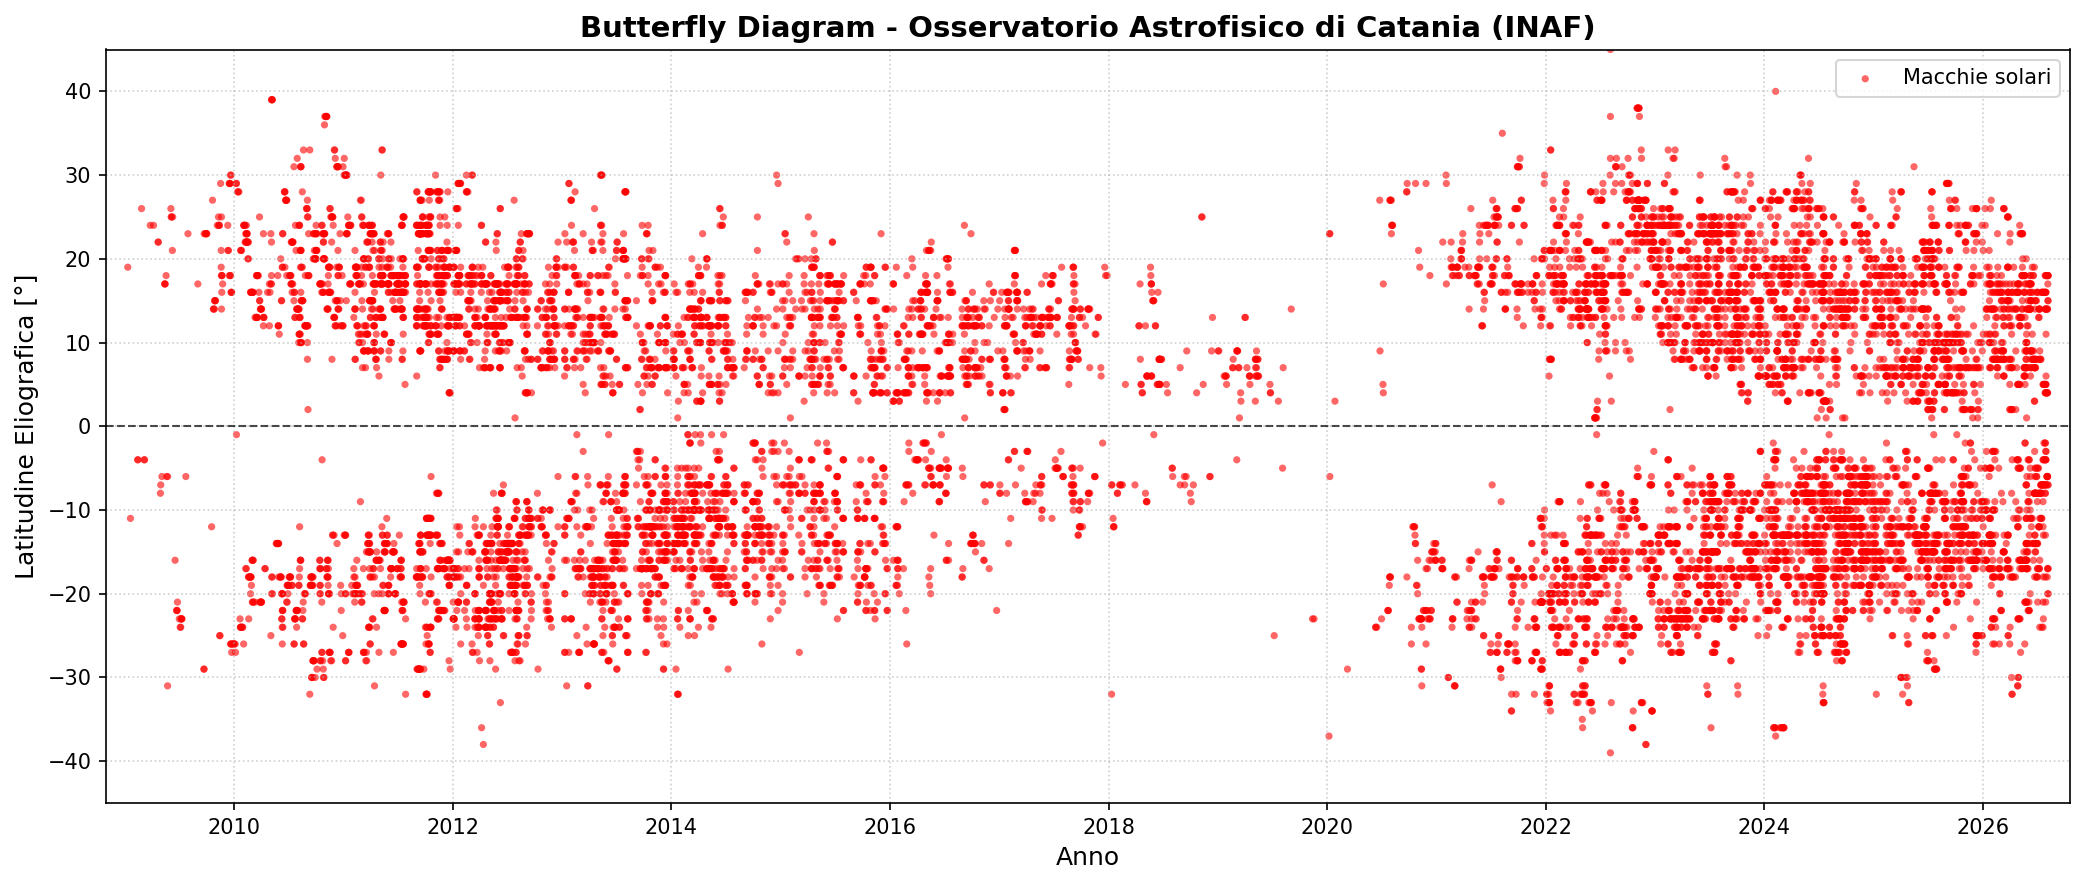

In [1]:
from datetime import datetime
import re
import matplotlib.pyplot as plt
import pandas as pd


def parse_and_plot_butterfly(filename_or_text):
    dates = []
    latitudes = []

    current_date = None

    # Se viene passato il percorso di un file, lo legge; altrimenti usa direttamente la stringa
    try:
        with open(filename_or_text, "r") as f:
            lines = f.readlines()
    except (FileNotFoundError, OSError):
        lines = filename_or_text.strip().split("\n")

    for line in lines:
        line = line.strip()
        if not line:
            continue

        # 1. Riconosciamo il cambio di file/data (es: dati_ussps_txt/090110.txt)
        match_file = re.search(r"(\d{6})\.txt", line)
        if match_file:
            yymmdd = match_file.group(1)
            # Convertiamo YYMMDD in oggetto datetime (es. 09 -> 2009, 26 -> 2026)
            dt = datetime.strptime(yymmdd, "%y%m%d")

            # Convertiamo la data in formato decimale (es. 2009.025)
            # per avere un asse X continuo e realistico
            year_start = datetime(dt.year, 1, 1)
            year_end = datetime(dt.year + 1, 1, 1)
            frac_year = dt.year + (dt - year_start) / (year_end - year_start)

            current_date = frac_year
            continue

        # 2. Riconosciamo i valori di latitudine (es: 19NE, 11SW, 04SE, 24NW)
        match_lat = re.match(r"^(\d{2})(NE|NW|SE|SW)$", line)
        if match_lat and current_date is not None:
            deg = int(match_lat.group(1))
            quadrant = match_lat.group(2)

            # Segno: Nord (+) / Sud (-)
            lat = deg if quadrant in ["NE", "NW"] else -deg

            dates.append(current_date)
            latitudes.append(lat)

    # Creazione DataFrame
    df = pd.DataFrame({"Year": dates, "Latitude": latitudes})

    # ==========================================
    # GRAFICO: BUTTERFLY DIAGRAM
    # ==========================================
    plt.figure(figsize=(14, 6), dpi=150)

    # Scatter plot dei dati
    plt.scatter(
        df["Year"],
        df["Latitude"],
        c="red",
        s=12,
        alpha=0.6,
        edgecolors="none",
        label="Macchie solari",
    )

    # Linea dell'equatore solare (Latitudine 0°)
    plt.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)

    # Formattazione assi e grafica
    plt.title(
        "Butterfly Diagram - Osservatorio Astrofisico di Catania (INAF)",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel("Anno", fontsize=12)
    plt.ylabel("Latitudine Eliografica [°]", fontsize=12)

    # Impostiamo i limiti realistici per il sole
    plt.ylim(-45, 45)
    plt.xlim(df["Year"].min() - 0.2, df["Year"].max() + 0.2)

    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper right")
    plt.tight_layout()

    # Mostra e salva il grafico
    plt.savefig("butterfly_diagram.png", dpi=300)
    plt.show()


# ==========================================
# ESECUZIONE
# ==========================================
if __name__ == "__main__":
    # Sostituisci con il nome del tuo file txt creato dal programma in C
    NOME_FILE = "lat.txt"
    parse_and_plot_butterfly(NOME_FILE)

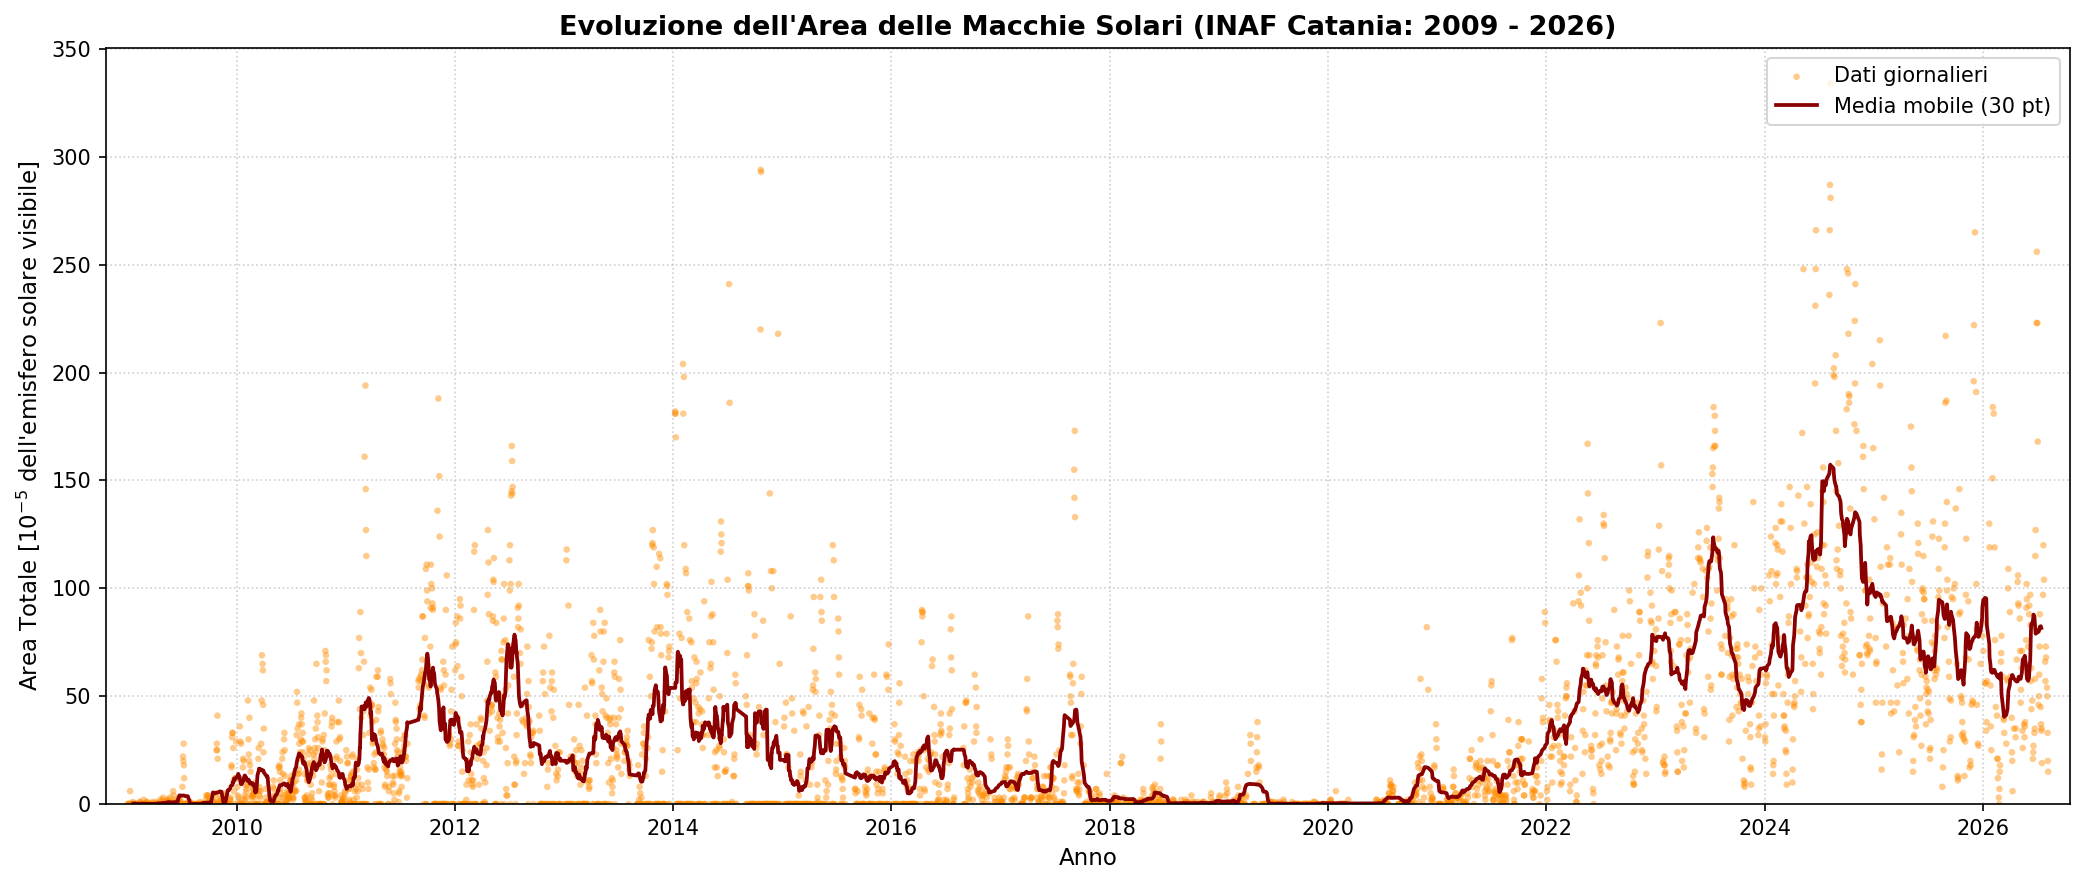

In [2]:
from datetime import datetime
import re
import matplotlib.pyplot as plt
import pandas as pd


def parse_and_plot_sunspot_area(file_path="area.txt"):
    dates = []
    areas = []
    current_year_frac = None

    with open(file_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        line = line.strip()
        if not line:
            continue

        # Estrae la data nel formato YYMMDD dal nome file
        match_file = re.search(r"(\d{6})\.txt", line)
        if match_file:
            yymmdd = match_file.group(1)
            dt = datetime.strptime(yymmdd, "%y%m%d")

            # Calcolo anno frazionario per ascisse temporali continue
            year_start = datetime(dt.year, 1, 1)
            year_end = datetime(dt.year + 1, 1, 1)
            current_year_frac = dt.year + (dt - year_start) / (
                year_end - year_start
            )
            continue

        # Estrae l'area associata alla data precedente
        if line.isdigit() and current_year_frac is not None:
            dates.append(current_year_frac)
            areas.append(int(line))
            current_year_frac = None

    df = pd.DataFrame({"Year": dates, "Area": areas})
    df = df.sort_values(by="Year").reset_index(drop=True)

    # Media mobile a 30 osservazioni per evidenziare il trend del ciclo solare
    df["Area_Smoothed"] = df["Area"].rolling(window=30, center=True).mean()

    # Creazione del grafico
    plt.figure(figsize=(14, 6), dpi=150)
    plt.scatter(
        df["Year"],
        df["Area"],
        color="darkorange",
        s=10,
        alpha=0.45,
        edgecolors="none",
        label="Dati giornalieri",
    )
    plt.plot(
        df["Year"],
        df["Area_Smoothed"],
        color="darkred",
        linewidth=1.8,
        label="Media mobile (30 pt)",
    )

    plt.title(
        "Evoluzione dell'Area delle Macchie Solari (INAF Catania: 2009 - 2026)",
        fontsize=13,
        fontweight="bold",
    )
    plt.xlabel("Anno", fontsize=11)
    plt.ylabel(
        "Area Totale [$10^{-5}$ dell'emisfero solare visibile]", fontsize=11
    )
    plt.xlim(df["Year"].min() - 0.2, df["Year"].max() + 0.2)
    plt.ylim(bottom=0)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper right")
    plt.tight_layout()

    plt.savefig("sunspot_area_evolution.png", dpi=300)
    plt.show()


if __name__ == "__main__":
    parse_and_plot_sunspot_area("sunspotsarea.txt")